<a href="https://colab.research.google.com/github/starkjiang/TrAC-Interpretability/blob/main/Interpretability_in_Ag_SHAP_LIME.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌽 Interpretability in AI: Shapley Values & LIME in Agriculture
### Post-hoc, model-agnostic explanations: *"Why did the model predict THIS for THIS field?"*
**Translational AI Center (TrAC), Iowa State University**: live session, ~50 min

> **Before you start:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (≈3 min).
> Everything except the image demo at the end runs fine on a CPU.

| ⏱ Time | Part | The question we answer |
|---|---|---|
| 0–5 min | **Recap & the agronomist's question** | Why did this field underperform? |
| 5–15 min | **Part 1: Shapley values from scratch** | How do we split credit fairly among inputs? |
| 15–27 min | **Part 2: SHAP in practice** | Local *and* global explanations, and when to trust them |
| 27–42 min | **Part 3: LIME** | Can a simple local model explain a complex one? Fields *and* photos |
| 42–50 min | **Head-to-head & wrap-up** | SHAP vs. LIME: when to use which |

## Recap: where we are
Last week we explained models **from the inside** (coefficients, tree importance, neurons). This week's methods are:

* **Post-hoc:** applied *after* training, to any already-trained model.
* **Model-agnostic:** they only need the model's `predict()` function. Random forest, XGBoost, neural net, or a vendor's black box all work.
* **Local:** they explain **one prediction at a time**. Many local explanations can be added up into a global picture.

We reuse last week's **800 simulated Iowa corn fields**. Because we generated the data, we know the *true* agronomy and can check
whether each explanation tells the truth.

> 🧑‍🌾 **The agronomist's question:** *"Your model predicts only ~70 bu/ac for this field, even though it got 240 lb of N. Why?"*

In [ ]:
#@title ⚙️ Setup: install SHAP & LIME, import libraries (≈30 s)
!pip -q install shap lime
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, itertools, math, time
import shap, lime, lime.lime_tabular
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_TRUE, C_RF, C_POS, C_NEG = "#2b2b2b", "#2e86ab", "#2a9d8f", "#d1495b"
print("SHAP", shap.__version__, "| LIME ready ✔")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
SHAP 0.54.1 | LIME ready ✔


In [ ]:
#@title 🔒 Simulate the 800 corn fields & train the "black box" (same data as last week)
rng = np.random.default_rng(2026); n = 800

# --- the TRUE agronomy (the answer key) ---
def f_nitrogen(N, rain): return 90 * (1 - np.exp(-N / 55)) * np.clip(1 - ((rain - 24) / 14) ** 2, 0.3, 1.0)
def f_rain(rain):        return -0.25 * (rain - 24) ** 2
def f_heat(h):           return -3.0 * h
def f_om(om):            return 6.0 * om
def f_ph(ph):            return -18 * (ph - 6.5) ** 2
def f_plant(doy):        return -0.9 * np.maximum(doy - 125, 0)
def true_yield(d):
    return (110 + f_nitrogen(d["nitrogen_lb_ac"], d["rain_in"]) + f_rain(d["rain_in"]) + f_heat(d["heat_days"])
            + f_om(d["organic_matter_pct"]) + f_ph(d["soil_pH"]) + f_plant(d["planting_doy"]))
    # soil_moisture_pct and field_id have NO effect on yield

rain = np.clip(rng.normal(22, 5, n), 8, 38)
df = pd.DataFrame({
    "nitrogen_lb_ac":     rng.uniform(0, 250, n),
    "rain_in":            rain,
    "soil_moisture_pct":  8 + 0.6 * rain + rng.normal(0, 0.8, n),     # sensor that tracks rain
    "heat_days":          np.clip(rng.poisson(6, n), 0, 25).astype(float),
    "organic_matter_pct": rng.uniform(1.5, 6.0, n),
    "soil_pH":            np.clip(rng.normal(6.5, 0.5, n), 5.0, 8.0),
    "planting_doy":       rng.uniform(105, 155, n),
    "field_id":           rng.permutation(n).astype(float),
})
df["yield_bu_ac"] = true_yield(df) + rng.normal(0, 10, n)
FEATURES = [c for c in df.columns if c != "yield_bu_ac"]
X, y = df[FEATURES], df["yield_bu_ac"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)

# the "black box" we want to explain
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0).fit(X_tr, y_tr)
print(f"Random forest R² on held-out fields: {r2_score(y_te, rf.predict(X_te)):.3f}")

# The field our agronomist is asking about: the lowest predicted yield in the test set
field = X_te.iloc[[int(np.argmin(rf.predict(X_te)))]]
print(f"\nField #{field.index[0]}: predicted {rf.predict(field)[0]:.0f} bu/ac, "
      f"average field ≈ {rf.predict(X_tr).mean():.0f} bu/ac")
field.T.round(1).rename(columns={field.index[0]: "this field"})

Random forest R² on held-out fields: 0.825

Field #651: predicted 71 bu/ac, average field ≈ 156 bu/ac


,this field
nitrogen_lb_ac,239.7
rain_in,8.0
soil_moisture_pct,13.0
heat_days,2.0
organic_matter_pct,4.1
soil_pH,6.9
planting_doy,138.7
field_id,237.0


---
# Part 1: Shapley values from scratch (game theory, 1953 🏆)

**The idea (Lloyd Shapley, Nobel Prize 2012):** a team of *players* earns a *payout*. How do we split it **fairly**?

| Game theory | Our model |
|---|---|
| players | input features (N, rain, heat, …) |
| payout | this field's prediction **minus** the average prediction |
| a "coalition" of players | a subset of features that we **know** for this field (the rest are filled in from typical fields) |

**Recipe:** add the players to the team **one at a time, in every possible order**. Each time a player joins, record how much the
prediction changes. A player's **Shapley value** is its *average* change over all orders.

Let's do it by hand with 3 players: **nitrogen, rain, heat**. The other inputs stay at this field's values.

In [ ]:
players = ["nitrogen_lb_ac", "rain_in", "heat_days"]
background = X_tr.sample(50, random_state=0)            # "typical fields" stand in for unknown inputs

def value(coalition):
    # Average prediction when we KNOW this field's values for `coalition` (and all non-players);
    # the remaining players take values from typical fields.
    d = background.copy()
    keep = [c for c in FEATURES if c not in players or c in coalition]
    d.loc[:, keep] = field[keep].values[0]          # broadcast this field's values to every row
    return rf.predict(d).mean()

# Step 1: the value of every coalition (2^3 = 8 of them)
v = {S: value(S) for k in range(4) for S in itertools.combinations(players, k)}
display(pd.DataFrame({"coalition (features we know)": [", ".join(S) or "∅ (none)" for S in v],
                      "avg prediction (bu/ac)": [round(x, 1) for x in v.values()]}))

# Step 2: every ordering → marginal contribution of each player
rows = []
for order in itertools.permutations(players):
    known, row = (), {}
    for p in order:
        before = v[tuple(sorted(known, key=players.index))]
        known = known + (p,)
        row[p] = v[tuple(sorted(known, key=players.index))] - before
    rows.append({"order": " → ".join(o.split("_")[0] for o in order), **row})
orders = pd.DataFrame(rows).set_index("order")
orders.loc["SHAPLEY VALUE (average)"] = orders.mean()
orders.round(1)

,coalition (features we know),avg prediction (bu/ac)
0,∅ (none),130.5
1,nitrogen_lb_ac,146.4
2,rain_in,71.4
3,heat_days,135.7
4,"nitrogen_lb_ac, rain_in",70.0
5,"nitrogen_lb_ac, heat_days",152.3
6,"rain_in, heat_days",72.4
7,"nitrogen_lb_ac, rain_in, heat_days",70.6


,nitrogen_lb_ac,rain_in,heat_days
order,,,
nitrogen → rain → heat,15.8,-76.4,0.6
nitrogen → heat → rain,15.8,-81.7,5.9
rain → nitrogen → heat,-1.4,-59.2,0.6
rain → heat → nitrogen,-1.8,-59.2,1.0
heat → nitrogen → rain,16.5,-81.7,5.2
heat → rain → nitrogen,-1.8,-63.3,5.2
SHAPLEY VALUE (average),7.2,-70.2,3.1


💬 Read the table: **rain** is the main reason this field is predicted low. Notice that **nitrogen's** contribution depends on the order:
added *after* rain, its effect is smaller. That is the **N × rain interaction**: N doesn't pay off in a drought.
Shapley averages over all orders, so no single order gets to decide.

### The general formula
$$\phi_j = \sum_{S \subseteq F\setminus\{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\Big[v(S\cup\{j\}) - v(S)\Big]$$
It is the same "average over all orderings" written as a weighted sum over coalitions. With all **8 features** there are $2^8 = 256$ coalitions.
Still small enough to compute exactly:

In [ ]:
def exact_shapley(model, x, bg, features):
    p = len(features); vals = {}
    for S in itertools.product([0, 1], repeat=p):                  # all 256 coalitions
        d = bg.copy(); m = np.array(S, bool)
        d.loc[:, np.array(features)[m]] = x[features].values[0, m]
        vals[S] = model.predict(d).mean()
    phi = np.zeros(p)
    for S, vS in vals.items():
        for j in range(p):
            if S[j] == 0:
                Sj = list(S); Sj[j] = 1; k = sum(S)
                phi[j] += math.factorial(k) * math.factorial(p - k - 1) / math.factorial(p) * (vals[tuple(Sj)] - vS)
    return phi, vals[(0,) * p]

t0 = time.time()
phi, base = exact_shapley(rf, field, background, FEATURES)
print(f"computed {2**len(FEATURES)} coalitions in {time.time()-t0:.1f}s\n")

# Compare with the SHAP library (TreeExplainer = an exact, fast algorithm for tree models)
tree_explainer = shap.TreeExplainer(rf, data=background, feature_perturbation="interventional")
sv_field = tree_explainer(field)
display(pd.DataFrame({"our formula": phi, "SHAP library": sv_field.values[0]}, index=FEATURES).round(2))

pred = rf.predict(field)[0]
print(f"Efficiency check: base value {base:.1f} + sum of Shapley values {phi.sum():+.1f} = {base + phi.sum():.1f}"
      f"  vs. model prediction {pred:.1f} ✔")

computed 256 coalitions in 29.9s



,our formula,SHAP library
nitrogen_lb_ac,8.73,8.73
rain_in,-59.09,-59.09
soil_moisture_pct,-24.95,-24.95
heat_days,3.90,3.90
organic_matter_pct,1.58,1.58
soil_pH,0.01,0.01
planting_doy,-0.93,-0.93
field_id,0.23,0.23


Efficiency check: base value 141.1 + sum of Shapley values -70.5 = 70.6  vs. model prediction 70.6 ✔


### ✅ Why Shapley values are the "fair" split
Shapley values are the **only** credit split with all four of these properties:
1. **Efficiency:** contributions add up exactly to *prediction − average*. Nothing is lost.
2. **Symmetry:** two features that contribute identically get identical credit.
3. **Dummy:** a feature the model never uses gets 0.
4. **Additivity:** for an ensemble (like a forest), the explanation of the average equals the average of the explanations.

The catch: exact computation doubles with every feature ($2^{20}$ ≈ 1 million coalitions for 20 features).
**SHAP** (Lundberg & Lee, NeurIPS 2017) provides fast algorithms: exact for trees, approximate for any model.

---
# Part 2: SHAP in practice

### 2.1 Local: the waterfall plot for our field
Start at the **average field** (E[f(x)]); each bar pushes the prediction up (red) or down (blue) until we reach **this field's** prediction.

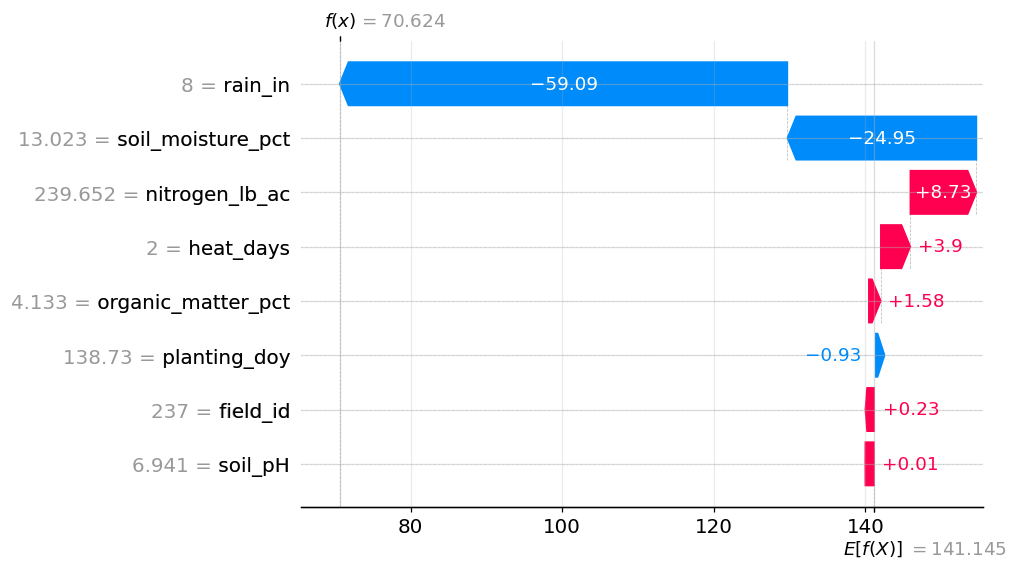

In [ ]:
shap.plots.waterfall(sv_field[0], max_display=9)

🧑‍🌾 **Answer to the agronomist:** a severe drought (8 in of rain) explains most of the shortfall. The high N rate added a little,
but with no water the crop couldn't use it.

🤔 **But look at `soil_moisture_pct`:** it gets a big share of the blame, even though in our answer key it has **zero** effect on yield.
It is a sensor that *tracks* rain, so the model uses it as a stand-in. **SHAP explains the model, not the field.** Correlated inputs
split the credit between them.

### 2.2 Global: explain every field, then summarize
Each dot is **one field**. Horizontal position = how much that feature pushed the field's prediction; color = the feature's value.

explained 240 fields in 7.1s


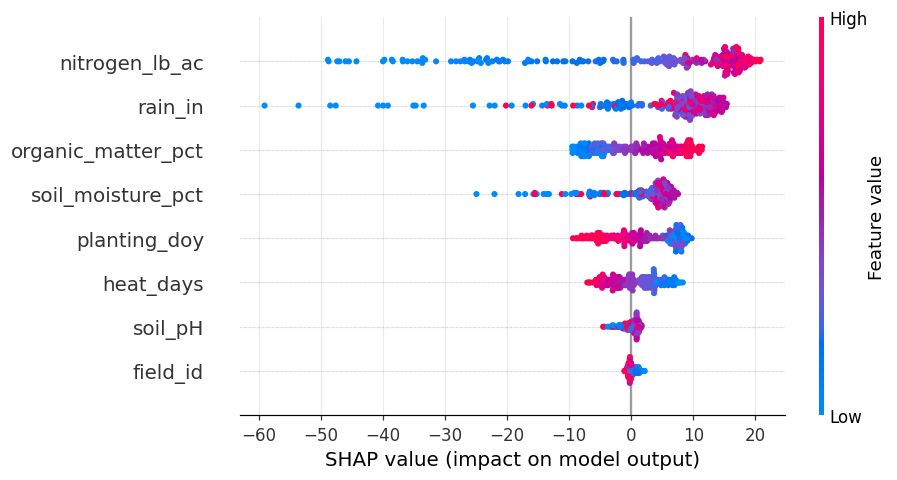

In [ ]:
t0 = time.time()
sv_all = tree_explainer(X_te)                          # 240 fields × 8 features
print(f"explained {len(X_te)} fields in {time.time()-t0:.1f}s")
shap.plots.beeswarm(sv_all, max_display=9)

How to read it:
* **N:** red (high N) on the right, blue (low N) far left. Zero N costs up to ~50 bu, but the red dots bunch together: **diminishing returns**.
* **Heat days:** high values (red) push yields down.
* **Rain:** low rain (blue) has a long tail to the left. **Drought is the biggest single risk** in this dataset.
* **`field_id`:** a tight band at 0, so the model correctly ignores it.

The mean |SHAP| bar chart below is a **global importance** measure built entirely from local explanations:

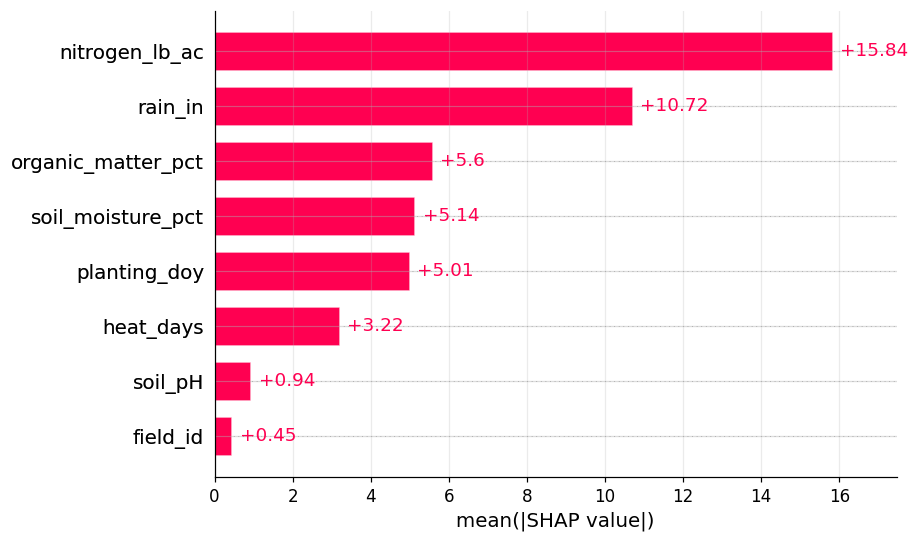

In [ ]:
shap.plots.bar(sv_all, max_display=9)

### 2.3 Dependence plot: SHAP rediscovers the N response *and* the interaction

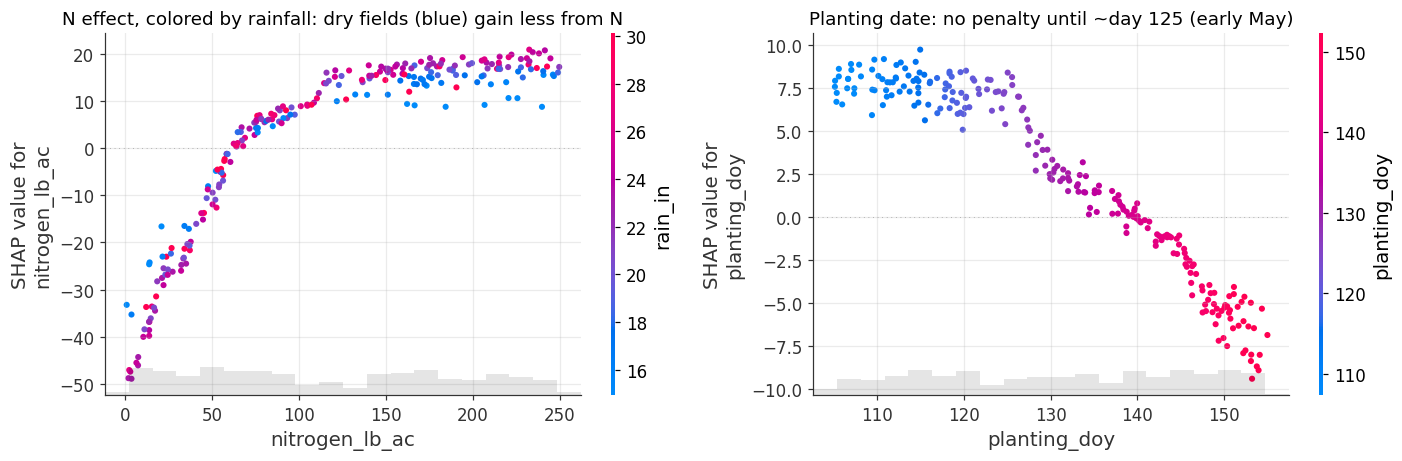

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
shap.plots.scatter(sv_all[:, "nitrogen_lb_ac"], color=sv_all[:, "rain_in"], ax=axes[0], show=False)
axes[0].set_title("N effect, colored by rainfall: dry fields (blue) gain less from N")
shap.plots.scatter(sv_all[:, "planting_doy"], color=sv_all[:, "planting_doy"], ax=axes[1], show=False)
axes[1].set_title("Planting date: no penalty until ~day 125 (early May)")
plt.tight_layout(); plt.show()

### 2.4 🔍 Does SHAP tell the truth? Check it against the answer key
For the effects that are purely **additive** in our answer key (heat, organic matter, pH, planting date), the true Shapley value of a
field is known exactly: *the field's true effect minus the average true effect*. Points on the diagonal mean SHAP got it right.

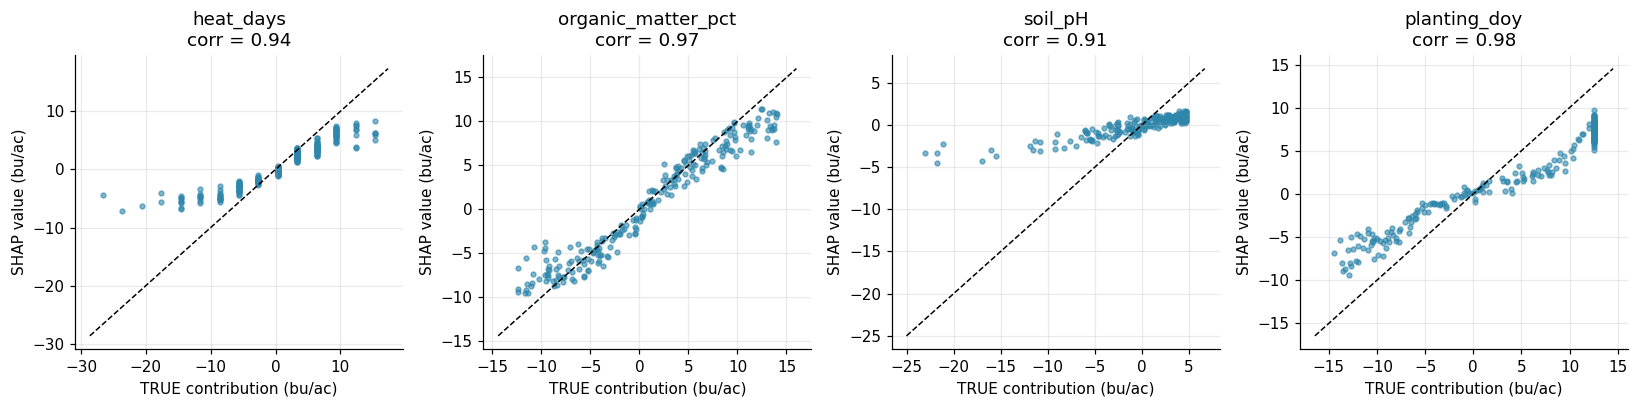

In [ ]:
checks = {"heat_days": f_heat, "organic_matter_pct": f_om, "soil_pH": f_ph, "planting_doy": f_plant}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (feat, f) in zip(axes, checks.items()):
    true_phi = f(X_te[feat]) - f(background[feat]).mean()
    est = sv_all[:, feat].values
    lim = [min(true_phi.min(), est.min()) - 2, max(true_phi.max(), est.max()) + 2]
    ax.scatter(true_phi, est, s=10, alpha=.6, color=C_RF); ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("TRUE contribution (bu/ac)"); ax.set_ylabel("SHAP value (bu/ac)")
    ax.set_title(f"{feat}\ncorr = {np.corrcoef(true_phi, est)[0, 1]:.2f}")
plt.tight_layout(); plt.show()

SHAP faithfully reports what the forest learned, but it is only as good as the model. Where the forest is weak (few fields with many heat
days, mild pH effects drowned in noise), the SHAP values are off too.

### 2.5 "Compared to what?" The baseline matters
A Shapley value always answers *"why is this field different from the **reference** fields?"* Change the reference and you change the story.
Below we explain the same field against **all fields** vs. against **other drought fields** (rain < 15 in).

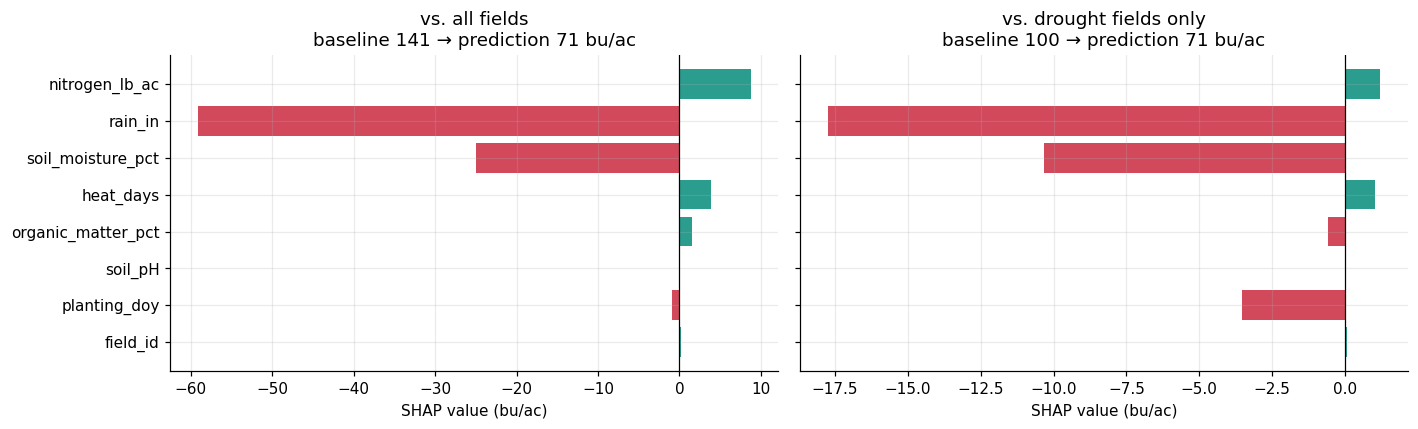

In [ ]:
refs = {"vs. all fields": background,
        "vs. drought fields only": X_tr[X_tr["rain_in"] < 15].sample(50, random_state=0, replace=True)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, bg) in zip(axes, refs.items()):
    e = shap.TreeExplainer(rf, data=bg, feature_perturbation="interventional")(field)
    vals = pd.Series(e.values[0], index=FEATURES)
    ax.barh(FEATURES, vals, color=[C_POS if v > 0 else C_NEG for v in vals])
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{name}\nbaseline {e.base_values[0]:.0f} → prediction {e.base_values[0] + vals.sum():.0f} bu/ac")
    ax.set_xlabel("SHAP value (bu/ac)")
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

Against other drought fields, rain is no longer "the problem" because they *all* had it. What stands out instead is how this field differs
from its peers. **Choose the baseline that matches the question your stakeholder is asking.**

### ✅ Part 2 takeaways
1. SHAP values **add up** to *prediction − baseline*: a complete, auditable credit split, in the target's units (bu/ac).
2. **Local → global:** beeswarm and bar plots summarize thousands of local explanations.
3. **Dependence plots** reveal non-linear effects and interactions (N × rain).
4. ⚠️ **Correlated inputs share credit** (rain vs. soil moisture). SHAP explains the *model*, not causal agronomy.
5. ⚠️ **The baseline is a choice.** Always say what you are comparing against.

---
# Part 3: LIME (Local Interpretable Model-agnostic Explanations)
**Ribeiro, Singh & Guestrin (KDD 2016).** A different idea:

> Any curve looks like a straight line if you zoom in enough. So **zoom in around one prediction** and fit a simple, readable model there.

**Recipe**
1. Create many **perturbed** versions of the input (nearby fields / partly hidden photos).
2. Ask the black box to predict each one.
3. **Weight** each sample by how close it is to the original.
4. Fit a **weighted linear model**. Its coefficients are the explanation.

### 3.1 LIME from scratch, in one dimension
Take a field with **60 lb N/ac** and ask: *what is the local effect of N here?* The blue curve is the forest's prediction as we vary N for this field.

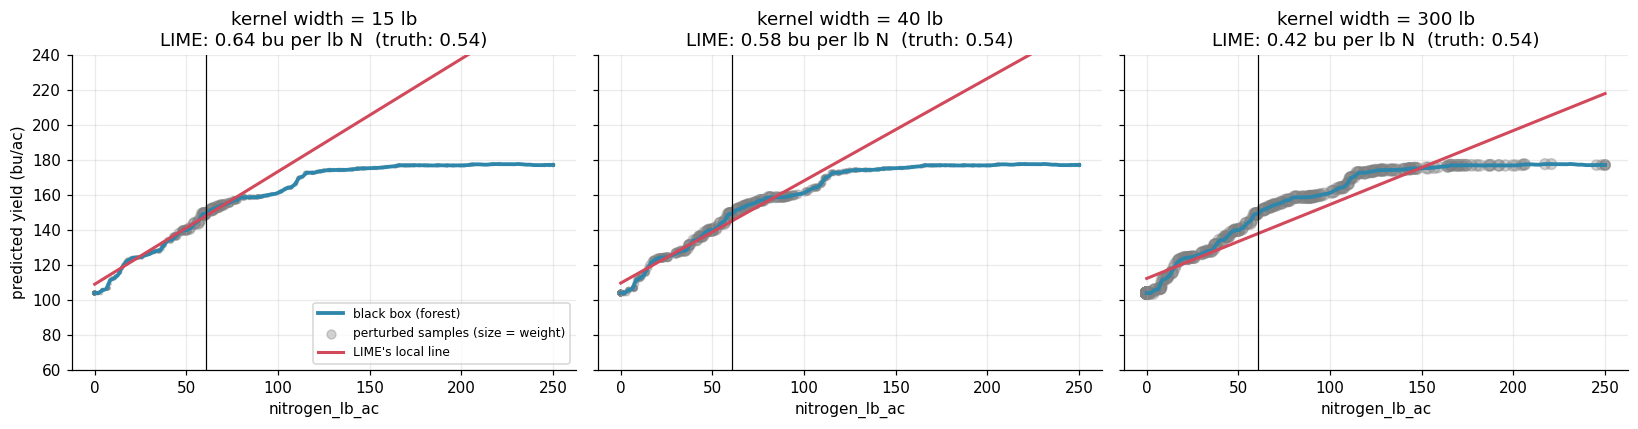

In [ ]:
f60 = X_te.iloc[[int(np.argmin(abs(X_te["nitrogen_lb_ac"] - 60) + 5 * abs(X_te["rain_in"] - 24)))]].copy()
N0 = f60["nitrogen_lb_ac"].iloc[0]
def bb(Ns):                                             # black box as a function of N only
    d = pd.concat([f60] * len(Ns)); d["nitrogen_lb_ac"] = Ns; return rf.predict(d)

grid = np.linspace(0, 250, 120)
r = np.random.default_rng(0)
Ns = np.clip(r.normal(N0, 80, 300), 0, 250)           # 1) perturb
preds = bb(Ns)                                         # 2) query the black box
true_slope = 90 / 55 * np.exp(-N0 / 55) * np.clip(1 - ((f60["rain_in"].iloc[0] - 24) / 14) ** 2, 0.3, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kw in zip(axes, [15, 40, 300]):                # kernel width = how local is "local"?
    w = np.exp(-((Ns - N0) ** 2) / kw ** 2)            # 3) weight by proximity
    lm = LinearRegression().fit(Ns[:, None], preds, sample_weight=w)   # 4) weighted linear fit
    ax.plot(grid, bb(grid), color=C_RF, lw=2.5, label="black box (forest)")
    ax.scatter(Ns, preds, s=4 + 60 * w, alpha=.35, color="grey", label="perturbed samples (size = weight)")
    ax.plot(grid, lm.predict(grid[:, None]), color=C_NEG, lw=2, label="LIME's local line")
    ax.axvline(N0, color="k", lw=.8)
    ax.set_title(f"kernel width = {kw} lb\nLIME: {lm.coef_[0]:.2f} bu per lb N  (truth: {true_slope:.2f})")
    ax.set_xlabel("nitrogen_lb_ac"); ax.set_ylim(60, 240)
axes[0].set_ylabel("predicted yield (bu/ac)"); axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

💡 **The kernel width decides the answer.** Narrow: *"the next lb of N is worth ~0.6 bu here"* (close to the true local slope).
Wide: LIME collapses into a global straight line and says something different. LIME has no single "correct" setting.
This is its main weakness, and you should always report the setting you used.

### 3.2 LIME on the full model (all 8 inputs) with the `lime` library
Back to our drought field. For tabular data, LIME turns each input into a readable **rule** such as `rain_in <= 18.6`
(based on the training data's quartiles) and fits a weighted linear model on those rules.

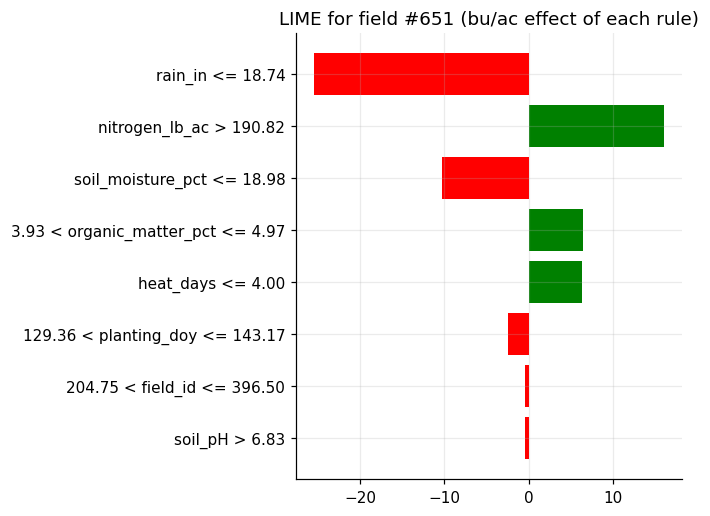

Fidelity check → LIME's simple model predicts 147 bu/ac for this field; the black box says 71.  Local fit R² = 0.37


In [ ]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_tr.values, feature_names=FEATURES, mode="regression", random_state=0)
predict_fn = lambda a: rf.predict(pd.DataFrame(a, columns=FEATURES))   # LIME only needs predict()

exp = lime_explainer.explain_instance(field.values[0], predict_fn, num_features=8, num_samples=3000)
exp.as_pyplot_figure(); plt.title(f"LIME for field #{field.index[0]} (bu/ac effect of each rule)")
plt.tight_layout(); plt.show()
print(f"Fidelity check → LIME's simple model predicts {exp.local_pred[0]:.0f} bu/ac for this field; "
      f"the black box says {rf.predict(field)[0]:.0f}.  Local fit R² = {exp.score:.2f}")

⚠️ **Always run the fidelity check.** LIME gets the *direction* right (drought hurts, N helps a bit, `field_id` is irrelevant),
but its simple model predicts far more than the black box does. The rule `rain_in <= 18.7` lumps this extreme **8-inch** drought field
together with mildly dry ones, so LIME **under-states** the drought.

If the local surrogate can't reproduce the black box's prediction, don't trust its numbers: try finer bins (`discretizer="decile"`),
more samples, or a different kernel width, or switch to SHAP.

### 3.3 ⚠️ Stability check: run LIME again
LIME relies on **random** sampling. Explain the *same* field five times with different random seeds (500 samples each):

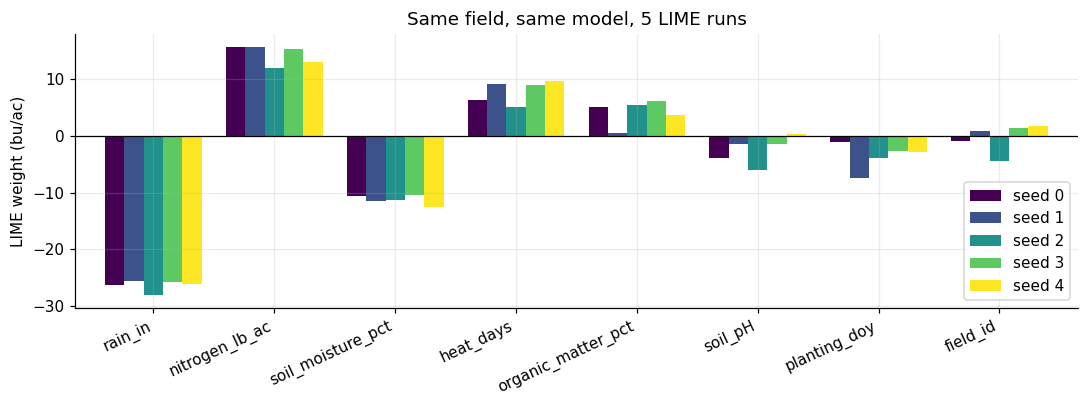

Spread across runs (std):


,rain_in,nitrogen_lb_ac,soil_moisture_pct,heat_days,organic_matter_pct,soil_pH,planting_doy,field_id
std,1.03,1.77,0.84,1.98,2.27,2.5,2.38,2.55


SHAP (TreeExplainer) gives the identical answer every time: it is exact and deterministic.


In [ ]:
runs = []
for seed in range(5):
    e = lime.lime_tabular.LimeTabularExplainer(X_tr.values, feature_names=FEATURES, mode="regression", random_state=seed)
    ex = e.explain_instance(field.values[0], predict_fn, num_features=8, num_samples=500)
    runs.append({FEATURES[i]: w for i, w in ex.as_map()[1]})   # label 1 = regression output
runs = pd.DataFrame(runs, index=[f"seed {s}" for s in range(5)])
ax = runs.T.plot.bar(figsize=(10, 3.8), width=.8, colormap="viridis")
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("LIME weight (bu/ac)"); ax.set_title("Same field, same model, 5 LIME runs")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
print("Spread across runs (std):"); display(runs.std().round(2).to_frame("std").T)
print("SHAP (TreeExplainer) gives the identical answer every time: it is exact and deterministic.")

Big effects (rain, nitrogen) are stable, but **small ones can flip sign** between runs. In practice: use many samples, repeat with a few seeds,
and only trust effects that stay the same across runs.

### 3.4 📷 LIME for images: what makes the network say "corn"?
LIME's most famous use is on images. Its "features" are **superpixels** (patches of similar color). LIME greys out random patches,
watches how the network's confidence changes, and fits a linear model saying which patches **support** or **oppose** a class.
We use the same pretrained **GoogLeNet** and photos as last week.

In [ ]:
#@title ⚙️ Load GoogLeNet + photos
import torch, requests, io, urllib.parse
from PIL import Image
from torchvision.models import googlenet, GoogLeNet_Weights
import torchvision.transforms as T
from lime import lime_image
from skimage.segmentation import mark_boundaries

device = "cuda" if torch.cuda.is_available() else "cpu"
weights = GoogLeNet_Weights.IMAGENET1K_V1
cnn = googlenet(weights=weights).eval().to(device)
CATS = weights.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
to_224 = T.Compose([T.Resize(224), T.CenterCrop(224)])

def load_commons(fnames):
    # Download a freely licensed photo from Wikimedia Commons (tries backups and thumbnail sizes)
    for fname in fnames:
        for suffix in ["?width=960", "?width=500", ""]:
            url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + urllib.parse.quote(fname) + suffix
            try:
                r = requests.get(url, headers={"User-Agent": "ISU-TrAC-interpretability-course/1.0 (educational use)"}, timeout=30)
                r.raise_for_status(); return Image.open(io.BytesIO(r.content)).convert("RGB")
            except Exception as e: last = e
    raise RuntimeError(f"download failed: {last}")

@torch.no_grad()
def predict_images(batch):
    # LIME's classifier_fn: (N, 224, 224, 3) floats in [0, 1] → (N, 1000) class probabilities
    x = torch.tensor(np.asarray(batch), dtype=torch.float32, device=device).permute(0, 3, 1, 2)
    return cnn((x - MEAN) / STD).softmax(-1).cpu().numpy()

PHOTOS = {"corn ears (USDA-ARS)": ["Zea_mays.jpg", "YellowCorn.jpg"],
          "tractor + chisel plow": ["JDTractor_chisel-plough.jpg", "John_Deere_8320.jpg"]}
imgs = {}
for name, f in PHOTOS.items():
    try: imgs[name] = np.asarray(to_224(load_commons(f))) / 255.0
    except Exception as e: print(f"⚠️ could not download {f[0]} ({e}). Use the upload cell at the end instead.")
N_SAMPLES = 1000 if device == "cuda" else 400
print("Device:", device, "| photos:", list(imgs))

Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 196MB/s]


Device: cuda | photos: ['corn ears (USDA-ARS)', 'tractor + chisel plow']


  0%|          | 0/1000 [00:00<?, ?it/s]

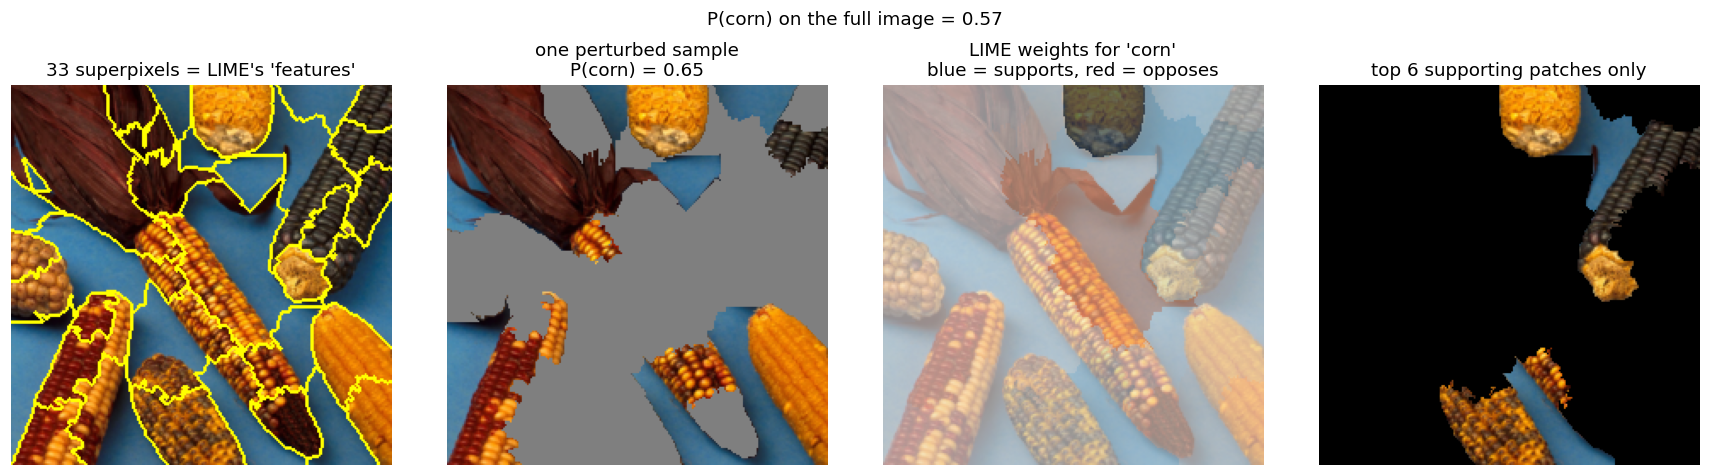

  0%|          | 0/1000 [00:00<?, ?it/s]

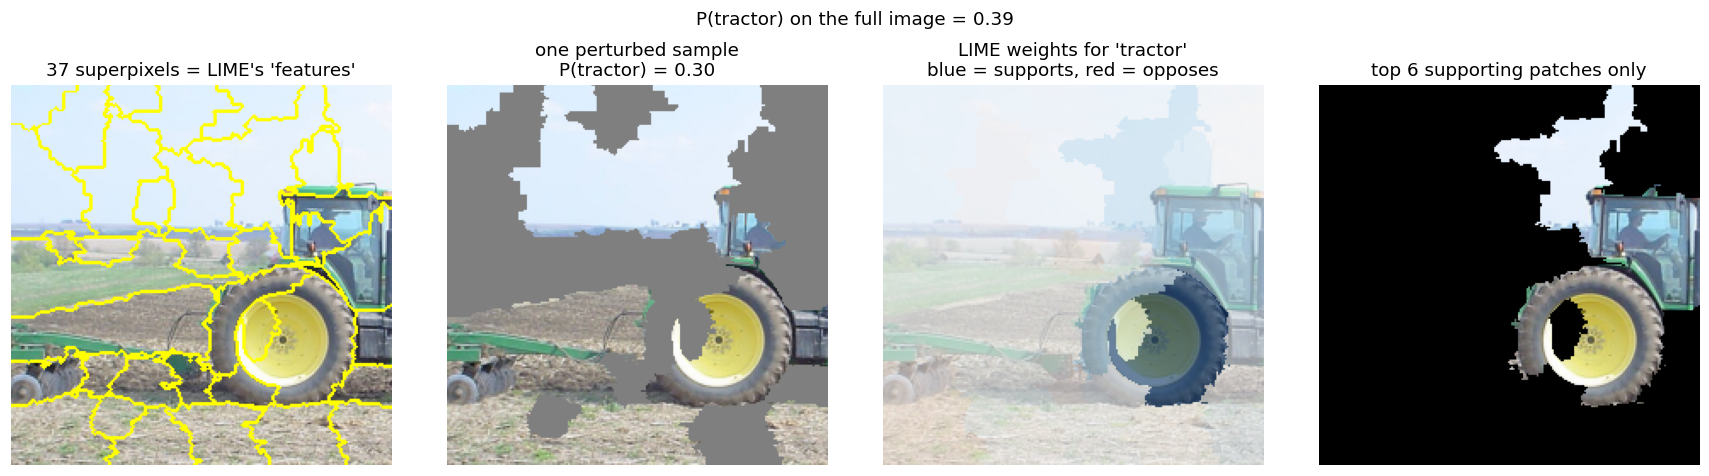

In [ ]:
def lime_image_panel(img, cls, n_samples=N_SAMPLES, n_show=6, seed=0):
    idx = CATS.index(cls)
    exp = lime_image.LimeImageExplainer(random_state=seed).explain_instance(
        img, predict_images, labels=(idx,), top_labels=None, hide_color=0.5,
        num_samples=n_samples, batch_size=50, random_seed=seed)
    seg = exp.segments
    wmap = np.zeros(seg.shape)
    for s, w in exp.local_exp[idx]: wmap[seg == s] = w
    # an example of what the network is shown: random superpixels greyed out
    r = np.random.default_rng(1); off = r.random(seg.max() + 1) < 0.5
    pert = img.copy(); pert[off[seg]] = 0.5
    temp, mask = exp.get_image_and_mask(idx, positive_only=True, num_features=n_show, hide_rest=True)
    lim = np.abs(wmap).max()
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    ax[0].imshow(mark_boundaries(img, seg)); ax[0].set_title(f"{seg.max() + 1} superpixels = LIME's 'features'")
    ax[1].imshow(pert); ax[1].set_title(f"one perturbed sample\nP({cls}) = {predict_images(pert[None])[0, idx]:.2f}")
    ax[2].imshow(img); ax[2].imshow(wmap, cmap="RdBu", vmin=-lim, vmax=lim, alpha=.6)
    ax[2].set_title(f"LIME weights for '{cls}'\nblue = supports, red = opposes")
    ax[3].imshow(temp); ax[3].set_title(f"top {n_show} supporting patches only")
    for a in ax: a.axis("off")
    plt.suptitle(f"P({cls}) on the full image = {predict_images(img[None])[0, idx]:.2f}", y=1.02)
    plt.tight_layout(); plt.show()

if "corn ears (USDA-ARS)" in imgs:  lime_image_panel(imgs["corn ears (USDA-ARS)"], "corn")
if "tractor + chisel plow" in imgs: lime_image_panel(imgs["tractor + chisel plow"], "tractor")

💬 **Discussion:** compare with last week's **Grad-CAM**. Grad-CAM needs the network's *gradients* (it is model-specific), while LIME only
calls `predict()`. That makes LIME usable on a vendor's API, but slower: hundreds to thousands of forward passes per image.
For a plant-disease classifier, ask: *are the supporting patches on the lesion, or on the background / tray / lighting?*

---
# Head-to-head: SHAP vs. LIME on the same field

KernelSHAP (model-agnostic) took 0.4s


,exact Shapley (TreeSHAP),KernelSHAP (black box),LIME weight (rule-based)
nitrogen_lb_ac,8.7,8.7,16.1
rain_in,-59.1,-59.1,-25.5
soil_moisture_pct,-24.9,-24.9,-10.3
heat_days,3.9,3.9,6.3
organic_matter_pct,1.6,1.6,6.4
soil_pH,0.0,0.0,-0.4
planting_doy,-0.9,-0.9,-2.5
field_id,0.2,0.2,-0.4


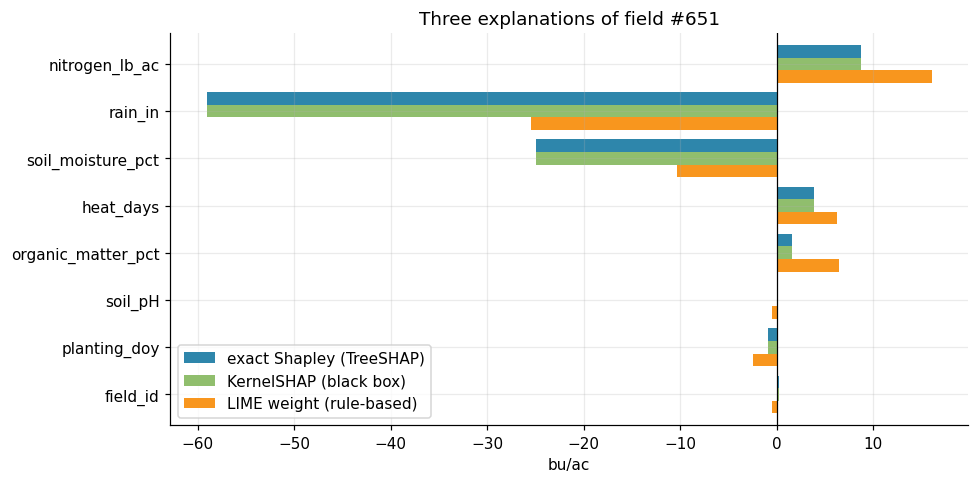

In [ ]:
# A fair comparison: KernelSHAP treats the forest as a pure black box, just like LIME does
t0 = time.time()
kernel = shap.KernelExplainer(predict_fn, background.values)
ks = kernel.shap_values(field.values, nsamples=1000, silent=True)[0]
print(f"KernelSHAP (model-agnostic) took {time.time()-t0:.1f}s")

lime_w = pd.Series({FEATURES[i]: w for i, w in exp.as_map()[1]})[FEATURES]
comp = pd.DataFrame({"exact Shapley (TreeSHAP)": sv_field.values[0],
                     "KernelSHAP (black box)": ks,
                     "LIME weight (rule-based)": lime_w.values}, index=FEATURES)
display(comp.round(1))
comp.plot.barh(figsize=(9, 4.5), width=.8, color=[C_RF, "#90be6d", "#f8961e"])
plt.axvline(0, color="k", lw=.8); plt.gca().invert_yaxis(); plt.xlabel("bu/ac")
plt.title(f"Three explanations of field #{field.index[0]}"); plt.tight_layout(); plt.show()

They agree on the **story** (drought dominates, N adds a little, the ID is irrelevant). KernelSHAP lands close to the exact values
using only `predict()`. LIME's numbers are smaller, as the fidelity check warned. The methods answer slightly different questions:
* **SHAP:** *"How do we fairly split (prediction − average) among the inputs?"* The values add up exactly.
* **LIME:** *"Which simple linear model mimics the black box near this field?"* The weights depend on the sampling and kernel choices.

| | **SHAP** | **LIME** |
|---|---|---|
| Foundation | cooperative game theory (axioms) | local surrogate model |
| Adds up to the prediction? | ✅ yes (efficiency) | ❌ not guaranteed |
| Stable across runs? | ✅ exact for trees; KernelSHAP close | ⚠️ depends on seed, samples, kernel width |
| Speed | ⚡ fast for trees; slow for general black boxes | moderate; images need many forward passes |
| Global view | ✅ beeswarm / bar / dependence plots | mostly local |
| Readable output | contributions in target units | human-readable rules (`rain <= 18.6`) |
| Shared pitfalls | correlated inputs, baseline choice, explains the *model* not the field | same |

**Rule of thumb:** use **TreeSHAP** for tree models (XGBoost, LightGBM, random forest). Use **LIME** for a quick, readable local check of
any black box, especially images and text. Use **KernelSHAP** when you need SHAP's guarantees for a non-tree model and can afford the compute.

In [ ]:
#@title 🔓 Reveal the answer key
print('''TRUE yield model used to simulate the fields:
  yield = 110
        + 90·(1 − e^(−N/55)) · rain_ok          ← N plateau; weaker in drought/flood (N × rain interaction)
        − 0.25·(rain − 24)²                      ← optimum rain ≈ 24 in
        − 3.0·heat_days                          ← heat stress
        + 6.0·organic_matter                     ← soil OM
        − 18·(pH − 6.5)²                         ← optimum pH ≈ 6.5
        − 0.9·max(planting_doy − 125, 0)         ← late-planting penalty after ~May 5
        + noise(sd = 10)
  soil_moisture_pct: NO direct effect (it just tracks rain): yet SHAP & LIME both blamed it!
  field_id:          NO effect at all''')

TRUE yield model used to simulate the fields:
  yield = 110
        + 90·(1 − e^(−N/55)) · rain_ok          ← N plateau; weaker in drought/flood (N × rain interaction)
        − 0.25·(rain − 24)²                      ← optimum rain ≈ 24 in
        − 3.0·heat_days                          ← heat stress
        + 6.0·organic_matter                     ← soil OM
        − 18·(pH − 6.5)²                         ← optimum pH ≈ 6.5
        − 0.9·max(planting_doy − 125, 0)         ← late-planting penalty after ~May 5
        + noise(sd = 10)
  soil_moisture_pct: NO direct effect (it just tracks rain): yet SHAP & LIME both blamed it!
  field_id:          NO effect at all


## 🎯 Wrap-up: three questions to take back to your team
1. When you show a SHAP waterfall to a grower or agronomist, **what is the baseline**, and is it the comparison they care about?
2. Which of your inputs are **correlated** (soil moisture & rain, yield-monitor data & harvest date, NDVI bands)? How will you
   report their credit, individually or as a group?
3. Is your LIME explanation **stable**? Re-run it with three seeds before you put it in a report.

📚 *Further reading:* Lundberg & Lee, **A Unified Approach to Interpreting Model Predictions** (NeurIPS 2017) · Ribeiro et al.,
**"Why Should I Trust You?"** (KDD 2016) · Molnar, **Interpretable Machine Learning**, chapters on Shapley values, SHAP and LIME (free online)

### 🏠 Try at home
* Pick the **highest**-yield field and explain it with SHAP and LIME.
* Drop `soil_moisture_pct`, retrain, and re-run the waterfall. Where does its credit go?
* In 3.4, change `"corn"` to `"ear"` or `"plow"`, or upload your own field photo below.

Saving potato.jpg to potato.jpg
potato.jpg → French loaf (20%), pomegranate (7%), buckeye (6%)


  0%|          | 0/1000 [00:00<?, ?it/s]

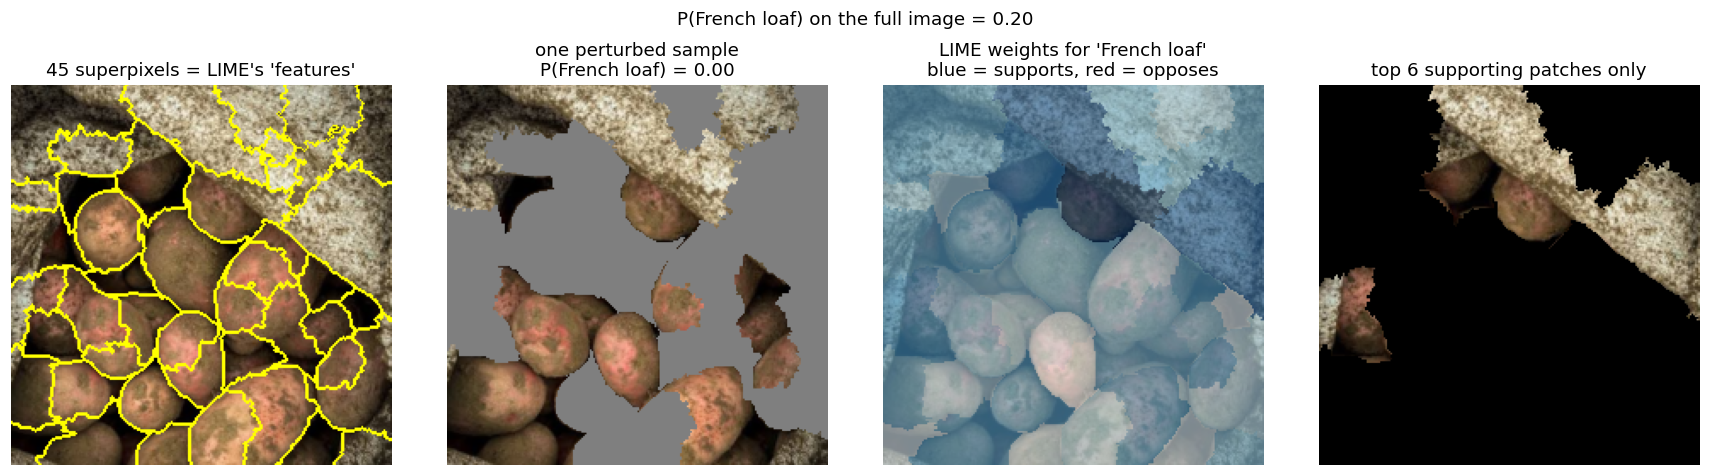

In [ ]:
#@title 📷 Bonus: LIME on your own photo (upload a .jpg/.png)
try:
    from google.colab import files
    for fname, data in files.upload().items():
        my = np.asarray(to_224(Image.open(io.BytesIO(data)).convert("RGB"))) / 255.0
        top = predict_images(my[None])[0].argsort()[::-1][:3]
        print(fname, "→", ", ".join(f"{CATS[i]} ({predict_images(my[None])[0, i]:.0%})" for i in top))
        lime_image_panel(my, CATS[top[0]])
except ImportError:
    print("Upload works in Google Colab only.")